# Healthcare Analytics for Doctor Visits

**Guiding question (from the dataset guide):** *Why do some people visit a doctor more often than others?*

This notebook analyses the `Healthcare Analytics for Doctor Visits.csv` file (5,190 people, 13 columns) described in `Dataset explanation.docx`. The outcome of interest is **`visits`**, the number of doctor visits. The remaining columns describe personal information, income, health, chronic conditions and healthcare support.

**Plan**

| # | Section | What we do |
|---|---------|-----------|
| 1 | Data overview | Load the file and check it against the dataset guide |
| 2 | Data preparation | Clean, encode and group the columns |
| 3 | The outcome: `visits` | See how doctor visits are distributed |
| 4 | The predictors | Profile who is in the data |
| 5 | Visits vs each factor | Compare groups and test the differences |
| 6 | How the factors relate to each other | Correlations and overlaps (confounding) |
| 7 | Statistical models | Separate the effect of each factor while holding the others fixed |
| 8 | Key findings and caveats | Plain-language conclusions |

**Requirements:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `statsmodels`, `scikit-learn`. The CSV must sit in the same folder as this notebook.

## 0. Setup

In [1]:
%matplotlib inline
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter, ScalarFormatter
import seaborn as sns
from scipy import stats

import patsy
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.precision", 3)

In [2]:
# Chart style: one calm palette (blue = focus, orange/aqua = extra categories,
# red = "negative" pole, grey = context / non-significant), hairline grid, thin marks.
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE, NEUTRAL = "#e1e0d9", "#c3c2b7", "#fcfcfb", "#f0efec"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK2,
    "xtick.color": BASELINE, "ytick.color": BASELINE,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": BASELINE, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
    "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.titlepad": 10, "axes.labelsize": 9.5,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9,
})

## 1. Data overview

First we load the CSV and confirm it matches what the dataset guide promises (**5,190 records, 13 columns**).

In [3]:
DATA_FILE = "Healthcare Analytics for Doctor Visits.csv"
raw = pd.read_csv(DATA_FILE)

assert raw.shape == (5190, 13), f"Unexpected shape {raw.shape}"
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}  ->  matches the dataset guide")
raw.head(8)

Rows: 5,190   Columns: 13  ->  matches the dataset guide


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no
5,6,1,female,0.19,0.35,5,1,9,no,no,no,yes,no
6,7,1,female,0.19,0.55,4,0,2,no,no,no,no,no
7,8,1,female,0.19,0.15,3,0,6,no,no,no,no,no


### Data dictionary

The table below reproduces the guide's definitions and adds what we actually observe in the file (type, missing values, distinct values, range).

In [4]:
guide = pd.DataFrame(
    [
        ("Unnamed: 0", "Record identifier",   "Row number (not a healthcare measurement)"),
        ("visits",     "Doctor visits",       "Number of times the person visited a doctor"),
        ("gender",     "Personal information", "male / female"),
        ("age",        "Personal information", "Age, stored as a decimal"),
        ("income",     "Financial information", "Income level"),
        ("illness",    "Health information",  "Number of illnesses reported"),
        ("reduced",    "Health impact",       "Days normal activities were reduced by health problems"),
        ("health",     "Health information",  "Numerical indicator of general health"),
        ("private",    "Healthcare support",  "Has private health cover (yes / no)"),
        ("freepoor",   "Healthcare support",  "Free care based on financial need (yes / no)"),
        ("freerepat",  "Healthcare support",  "Free care via a repatriation-related programme (yes / no)"),
        ("nchronic",   "Chronic condition",   "Has a chronic condition (yes / no)"),
        ("lchronic",   "Chronic condition",   "Has a long-term chronic condition (yes / no)"),
    ],
    columns=["column", "category (guide)", "meaning (guide)"],
).set_index("column")

observed = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "distinct": raw.nunique(),
    "min": raw.min(numeric_only=True),
    "max": raw.max(numeric_only=True),
})
guide.join(observed)

,category (guide),meaning (guide),dtype,missing,distinct,min,max
column,,,,,,,
Unnamed: 0,Record identifier,Row number (not a healthcare measurement),int64,0,5190,1.00,5190.00
visits,Doctor visits,Number of times the person visited a doctor,int64,0,10,0.00,9.00
gender,Personal information,male / female,str,0,2,NaN,NaN
age,Personal information,"Age, stored as a decimal",float64,0,12,0.19,0.72
income,Financial information,Income level,float64,0,14,0.00,1.50
illness,Health information,Number of illnesses reported,int64,0,6,0.00,5.00
reduced,Health impact,Days normal activities were reduced by health ...,int64,0,15,0.00,14.00
health,Health information,Numerical indicator of general health,int64,0,13,0.00,12.00
private,Healthcare support,Has private health cover (yes / no),str,0,2,NaN,NaN


### Quality checks

Before analysing, check for missing values, impossible values and duplicates.

In [5]:
n_dup = raw.drop(columns="Unnamed: 0").duplicated().sum()

print(f"Missing values (all columns):        {int(raw.isna().sum().sum())}")
print(f"ID column is 1..N and unique:        {raw['Unnamed: 0'].tolist() == list(range(1, len(raw) + 1))}")
print(f"Negative counts / days anywhere:     {bool((raw[['visits', 'illness', 'reduced', 'health']] < 0).any().any())}")
print(f"yes/no columns hold only yes / no:   "
      f"{all(set(raw[c].unique()) <= {'yes', 'no'} for c in ['private','freepoor','freerepat','nchronic','lchronic'])}")
print(f"Rows identical on every measurement: {n_dup:,}  ({n_dup / len(raw):.1%})")

Missing values (all columns):        0
ID column is 1..N and unique:        True
Negative counts / days anywhere:     False
yes/no columns hold only yes / no:   True
Rows identical on every measurement: 1,320  (25.4%)


**Reading the checks.** The file is complete: no missing values, no impossible values, and the ID column is a plain 1…5,190 sequence.

The 1,320 "duplicate" rows are **not errors**. The file has no person-level identifier, `age` takes only 12 distinct values, and most other columns are small counts or yes/no flags, so many different people naturally give the same set of answers. We keep them all.

## 2. Data preparation

What we do, and why:

* **Drop `Unnamed: 0`.** It is only a row number, so it carries no information about health.
* **Turn yes/no into 1/0** so the columns can be averaged, correlated and used in models. `gender` becomes a `female` flag.
* **Convert `age` to years.** The guide says age is stored as a decimal. Values run from 0.19 to 0.72 in 12 steps, which only makes sense as years ÷ 100 (19 to 72 years), so `age_years = age × 100`.
* **Create readable groups** (age, income, days of reduced activity, health score, coverage, chronic condition) for charts and tables.

In [6]:
df = raw.drop(columns="Unnamed: 0").copy()

# --- yes/no -> 1/0, gender -> female flag, age -> years -----------------------------------
yes_no = ["private", "freepoor", "freerepat", "nchronic", "lchronic"]
for c in yes_no:
    df[c] = (df[c] == "yes").astype(int)
df["female"] = (df["gender"] == "female").astype(int)
df["gender"] = df["gender"].str.capitalize()
df["age_years"] = (df["age"] * 100).round().astype(int)
df["any_visit"] = (df["visits"] > 0).astype(int)

# --- readable groups (ordered, so charts keep a sensible left-to-right order) -------------
df["age_group"] = pd.cut(df["age_years"], [0, 24, 44, 64, 120],
                         labels=["Under 25", "25-44", "45-64", "65+"])
df["income_group"] = pd.cut(df["income"], [-0.001, 0.2, 0.4, 0.7, 2.0],
                            labels=["<= 0.20", "0.21-0.40", "0.41-0.70", "> 0.70"])
df["reduced_group"] = pd.cut(df["reduced"], [-1, 0, 3, 13, 14],
                             labels=["0", "1-3", "4-13", "14 (max)"])
df["health_group"] = pd.cut(df["health"], [-1, 0, 1, 2, 4, 12],
                            labels=["0", "1", "2", "3-4", "5+"])

# The three "healthcare support" flags and the two "chronic" flags turn out to be
# mutually exclusive (checked below), so each set is really ONE categorical variable.
assert (df[["private", "freepoor", "freerepat"]].sum(axis=1) <= 1).all()
assert (df[["nchronic", "lchronic"]].sum(axis=1) <= 1).all()

cov_order = ["None of the three", "Private", "Free (low income)", "Free (repatriation)"]
df["coverage"] = pd.Categorical(
    np.select([df["private"] == 1, df["freepoor"] == 1, df["freerepat"] == 1],
              ["Private", "Free (low income)", "Free (repatriation)"],
              default="None of the three"),
    categories=cov_order, ordered=True)

chr_order = ["No chronic condition", "nchronic only", "lchronic only"]
df["chronic"] = pd.Categorical(
    np.select([df["lchronic"] == 1, df["nchronic"] == 1],
              ["lchronic only", "nchronic only"], default="No chronic condition"),
    categories=chr_order, ordered=True)

df.head()

,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic,female,age_years,any_visit,age_group,income_group,reduced_group,health_group,coverage,chronic
0,1,Female,0.19,0.55,1,4,1,1,0,0,0,0,1,19,1,Under 25,0.41-0.70,4-13,1,Private,No chronic condition
1,1,Female,0.19,0.45,1,2,1,1,0,0,0,0,1,19,1,Under 25,0.41-0.70,1-3,1,Private,No chronic condition
2,1,Male,0.19,0.90,3,0,0,0,0,0,0,0,0,19,1,Under 25,> 0.70,0,0,None of the three,No chronic condition
3,1,Male,0.19,0.15,1,0,0,0,0,0,0,0,0,19,1,Under 25,<= 0.20,0,0,None of the three,No chronic condition
4,1,Male,0.19,0.45,2,5,1,0,0,0,1,0,0,19,1,Under 25,0.41-0.70,4-13,1,None of the three,nchronic only


In [7]:
print("Coverage flags (private / freepoor / freerepat) - how many people in each combination:")
print(df.groupby(["private", "freepoor", "freerepat"]).size().rename("people").reset_index().to_string(index=False))
print()
print("Chronic flags (nchronic / lchronic) - how many people in each combination:")
print(df.groupby(["nchronic", "lchronic"]).size().rename("people").reset_index().to_string(index=False))

Coverage flags (private / freepoor / freerepat) - how many people in each combination:
 private  freepoor  freerepat  people
       0         0          0    1579
       0         0          1    1091
       0         1          0     222
       1         0          0    2298

Chronic flags (nchronic / lchronic) - how many people in each combination:
 nchronic  lchronic  people
        0         0    2493
        0         1     605
        1         0    2092


**Two structural findings that matter for the rest of the analysis**

1. **Nobody has more than one kind of coverage.** `private`, `freepoor` and `freerepat` never overlap. Together they split people into four groups: private cover (2,298), free cover for low income (222), free cover via repatriation (1,091), and **none of the three** (1,579).
2. **Nobody has both chronic flags.** `nchronic` and `lchronic` split people into three groups: no chronic condition (2,493), `nchronic` only (2,092), and `lchronic` only (605).

So these flags are really two categorical variables spread over five columns. The "none" groups act as the natural baseline when we fit models later.

### Notes on units (background, not in the guide)

The guide leaves some units open. The dataset appears to be the well-known *Australian Health Survey 1977-78* data (published as `DoctorVisits` in the R package `AER`). From that source: `visits`, `illness` and `reduced` all refer to a **two-week window**; `health` is a questionnaire score where **higher means worse health**; `income` is annual income in units of A$10,000; `nchronic` is a chronic condition that does **not** limit activity and `lchronic` one that **does**. Treat this as context to verify. Two checks in the file support it: `reduced` is capped at **14** (the length of a two-week window), and the `lchronic` group has far more reduced-activity days (shown later). The analysis below does not depend on these details; they only help with interpretation.

## 3. The outcome: how many doctor visits?

`visits` is a **count** (0, 1, 2, …). Counts behave differently from a bell-shaped variable, so we look at the shape first.

In [8]:
v = df["visits"]
summary = pd.DataFrame({
    "people": [len(v)],
    "mean": [v.mean()],
    "median": [v.median()],
    "variance": [v.var()],
    "max": [v.max()],
    "share with 0 visits": [(v == 0).mean()],
    "share with 2+ visits": [(v >= 2).mean()],
}, index=["visits"])
summary.style.format({"mean": "{:.3f}", "variance": "{:.3f}", "share with 0 visits": "{:.1%}",
                      "share with 2+ visits": "{:.1%}", "people": "{:,}"})

,people,mean,median,variance,max,share with 0 visits,share with 2+ visits
visits,"5,190",0.302,0.000000,0.637,9,79.8%,5.1%


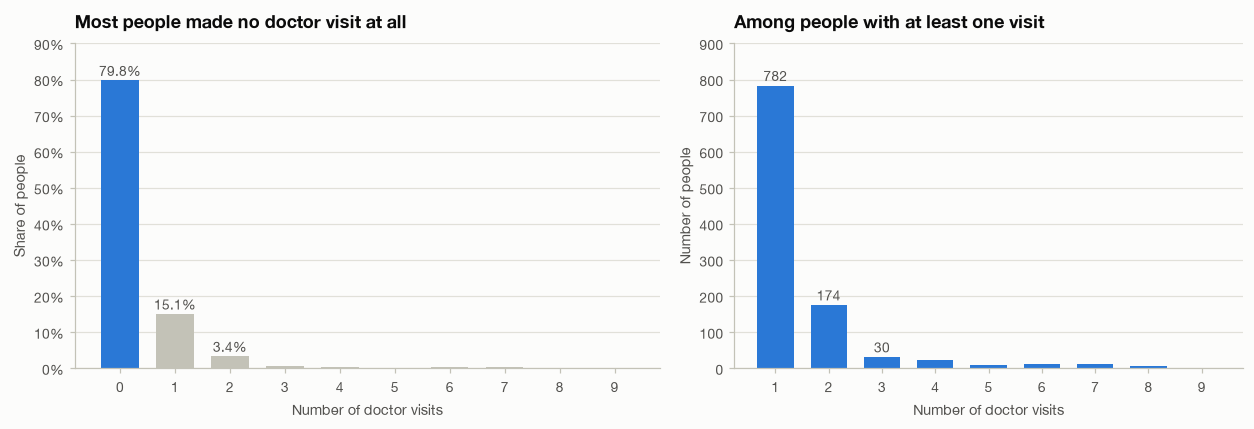

In [9]:
counts = v.value_counts().sort_index()
share = counts / len(v) * 100

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), gridspec_kw={"width_ratios": [1.15, 1]})

# Left: everyone. Emphasis on the zero bar; the rest in grey.
ax = axes[0]
ax.bar(share.index, share.values, width=0.68, color=[BLUE] + [BASELINE] * (len(share) - 1))
for k in (0, 1, 2):
    ax.text(k, share[k] + 1.2, f"{share[k]:.1f}%", ha="center", fontsize=9, color=INK2)
ax.set_title("Most people made no doctor visit at all")
ax.set_xlabel("Number of doctor visits")
ax.set_ylabel("Share of people")
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_xticks(share.index)
ax.set_ylim(0, 90)

# Right: zoom on the people who did visit (counts, because the shares are tiny).
ax = axes[1]
pos = counts[counts.index >= 1]
ax.bar(pos.index, pos.values, width=0.68, color=BLUE)
for k in (1, 2, 3):
    ax.text(k, pos[k] + 14, f"{pos[k]:,}", ha="center", fontsize=9, color=INK2)
ax.set_title("Among people with at least one visit")
ax.set_xlabel("Number of doctor visits")
ax.set_ylabel("Number of people")
ax.set_xticks(pos.index)
ax.set_ylim(0, 900)

fig.tight_layout()
plt.show()

**What the outcome looks like**

* **Doctor visits are rare.** About **80% of people (79.8%) made no visit**, 15.1% made exactly one and 3.4% two. Only about 1.8% made three or more, with a maximum of 9.
* **The average is low (0.30) but the spread is not.** The variance (0.64) is more than **twice the mean** (ratio 2.11). Counts with that much extra spread (called *overdispersion*) are not well described by a simple Poisson model, which assumes variance = mean. This is why Section 7 compares several count models.
* The median is 0, so averages are driven by the minority who visit. Throughout the notebook we therefore look at both **average visits** and **the share who visited at least once**.

## 4. The predictors: who is in the data?

Before comparing groups, profile the people in the file: their age, income, illness history, reduced-activity days, health score, gender, coverage and chronic condition.

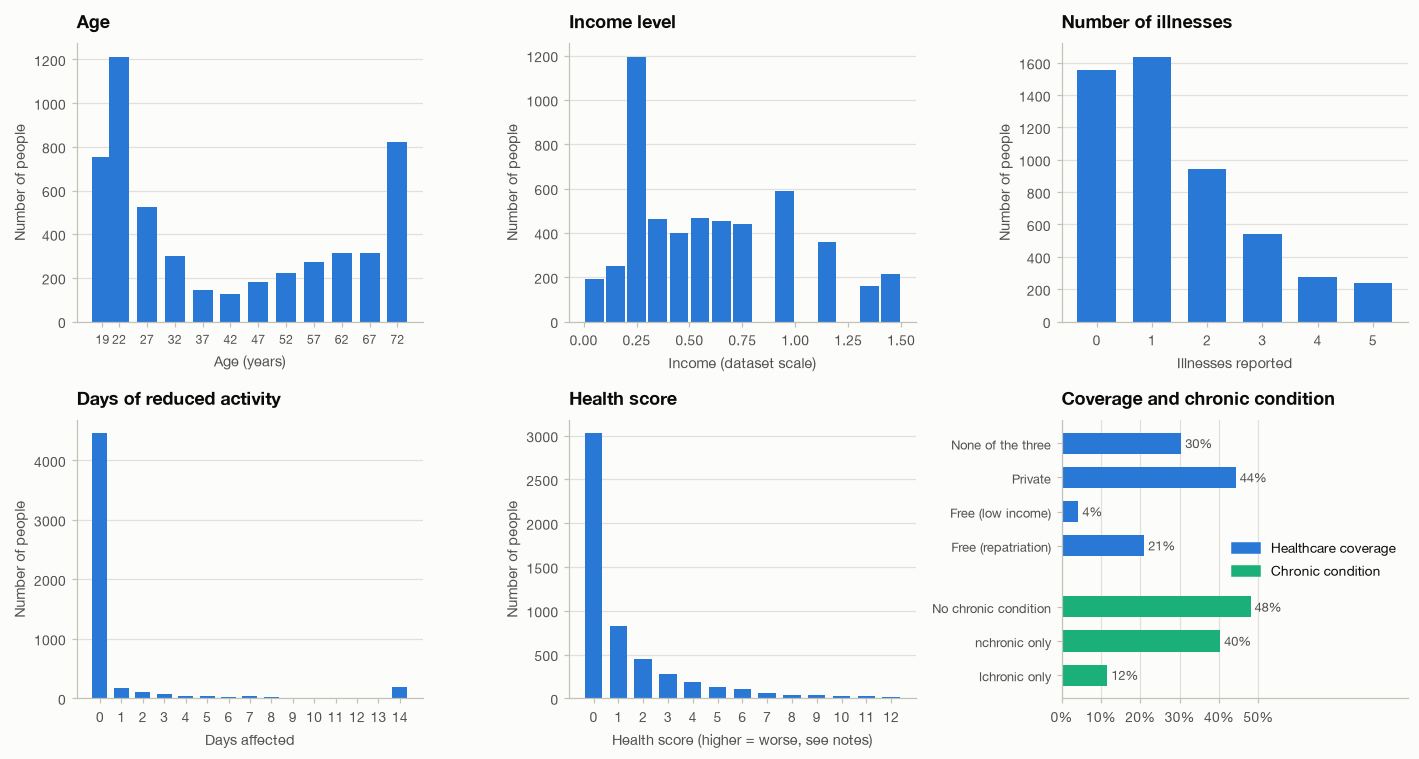

Female: 52.1%   |   Age range: 19-72 years   |   Median income: 0.55   |   No illness reported: 29.9%   |   Zero reduced days: 85.8%   |   14 reduced days: 3.6%


In [10]:
def count_bar(ax, series, title, xlabel, ticks=None, width=0.7):
    c = series.value_counts().sort_index()
    ax.bar(c.index, c.values, width=width, color=BLUE)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of people")
    if ticks is not None:
        ax.set_xticks(ticks)


fig, axes = plt.subplots(2, 3, figsize=(13, 7))
count_bar(axes[0, 0], df["age_years"], "Age", "Age (years)", sorted(df["age_years"].unique()), width=3.6)
axes[0, 0].tick_params(axis="x", labelsize=8)

ax = axes[0, 1]
ax.hist(df["income"], bins=np.arange(0, 1.55, 0.1), color=BLUE, rwidth=0.88)
ax.set_title("Income level"); ax.set_xlabel("Income (dataset scale)"); ax.set_ylabel("Number of people")

count_bar(axes[0, 2], df["illness"], "Number of illnesses", "Illnesses reported", range(0, 6))
count_bar(axes[1, 0], df["reduced"], "Days of reduced activity", "Days affected", range(0, 15))
count_bar(axes[1, 1], df["health"], "Health score", "Health score (higher = worse, see notes)", range(0, 13))

# Last panel: the two health-related yes/no groupings, as shares.
ax = axes[1, 2]
cov = df["coverage"].value_counts(normalize=True).reindex(cov_order) * 100
chr_ = df["chronic"].value_counts(normalize=True).reindex(chr_order) * 100
labels = list(cov.index) + list(chr_.index)
vals = list(cov.values) + list(chr_.values)
ypos = list(range(len(cov))) + [len(cov) + 0.8 + i for i in range(len(chr_))]
ax.barh(ypos, vals, height=0.62, color=[BLUE] * len(cov) + [AQUA] * len(chr_))
ax.set_yticks(ypos)
ax.set_yticklabels(labels, fontsize=8.5)
ax.invert_yaxis()
for y, val in zip(ypos, vals):
    ax.text(val + 1, y, f"{val:.0f}%", va="center", fontsize=8.5, color=INK2)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_xlim(0, 88)
ax.set_xticks(range(0, 51, 10))
ax.set_title("Coverage and chronic condition")
ax.legend(handles=[Patch(color=BLUE, label="Healthcare coverage"), Patch(color=AQUA, label="Chronic condition")],
          loc="center right")

fig.tight_layout()
plt.show()

print(f"Female: {df['female'].mean():.1%}   |   Age range: {df['age_years'].min()}-{df['age_years'].max()} years   |   "
      f"Median income: {df['income'].median():.2f}   |   No illness reported: {(df['illness'] == 0).mean():.1%}   |   "
      f"Zero reduced days: {(df['reduced'] == 0).mean():.1%}   |   14 reduced days: {(df['reduced'] == 14).mean():.1%}")

**What the predictors look like**

* **Age** is lumpy: 12 coarse values from 19 to 72. Many people are in their late teens/early twenties (1,965 under 25) and the single largest value is 72 (822 people, 16%). The guide does not say whether 72 is a cap, so we treat the values as age brackets.
* **Income** is also coded in steps; 0.25 is the most common value (1,195 people, 23%).
* **Health problems are concentrated in a minority.** 30% reported no illness, 58% have a health score of 0, and 86% had **no** reduced-activity days. A further 3.6% sit at exactly 14, the largest possible value, a spike that suggests a two-week window.
* **Coverage:** 44% private, 30% none of the three, 21% free via repatriation, only 4% free for low income. **Chronic condition:** 48% none, 40% `nchronic` only, 12% `lchronic` only.
* The sample is balanced by gender (52% female).

## 5. Visits compared across each factor

Here we ask, one factor at a time: **do people in this group visit the doctor more often?**

Each bar shows the *average number of visits* for a group, with a thin line for the 95% confidence interval (the range the true average plausibly lies in). The `n` under each label is the group size; short intervals mean a precise estimate, long intervals mean a small or very variable group.

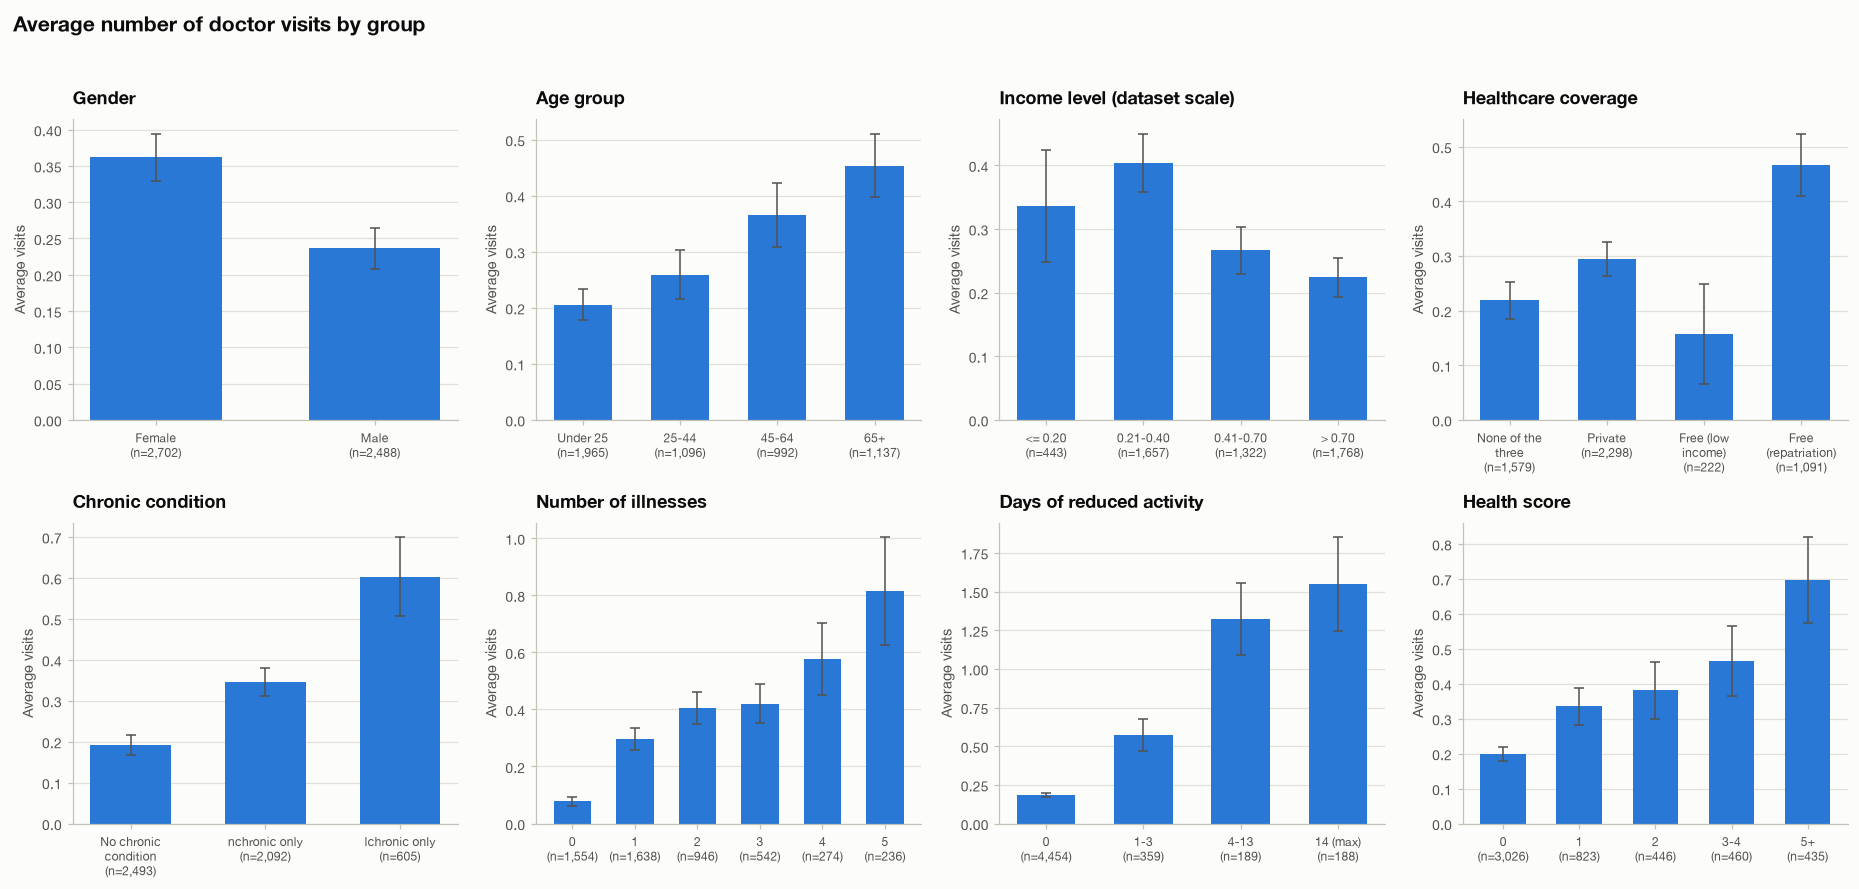

In [11]:
def group_panel(ax, col, title, value="visits", pct=False):
    g = df.groupby(col, observed=True)[value].agg(["mean", "std", "size"])
    scale = 100 if pct else 1
    mean, ci = g["mean"] * scale, 1.96 * g["std"] / np.sqrt(g["size"]) * scale
    x = np.arange(len(g))
    ax.bar(x, mean, width=0.6, color=BLUE)
    ax.errorbar(x, mean, yerr=ci, fmt="none", ecolor=INK2, elinewidth=1, capsize=3, capthick=1)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{textwrap.fill(str(i), 14, break_long_words=False)}\n(n={n:,})" for i, n in zip(g.index, g["size"])], fontsize=8)
    ax.set_title(title)
    if pct:
        ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    return g


panels = [("gender", "Gender"), ("age_group", "Age group"), ("income_group", "Income level (dataset scale)"),
          ("coverage", "Healthcare coverage"), ("chronic", "Chronic condition"),
          ("illness", "Number of illnesses"), ("reduced_group", "Days of reduced activity"),
          ("health_group", "Health score")]

fig, axes = plt.subplots(2, 4, figsize=(17, 8.2), sharey=False)
for ax, (col, title) in zip(axes.ravel(), panels):
    group_panel(ax, col, title)
    ax.set_ylabel("Average visits")
fig.suptitle("Average number of doctor visits by group", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

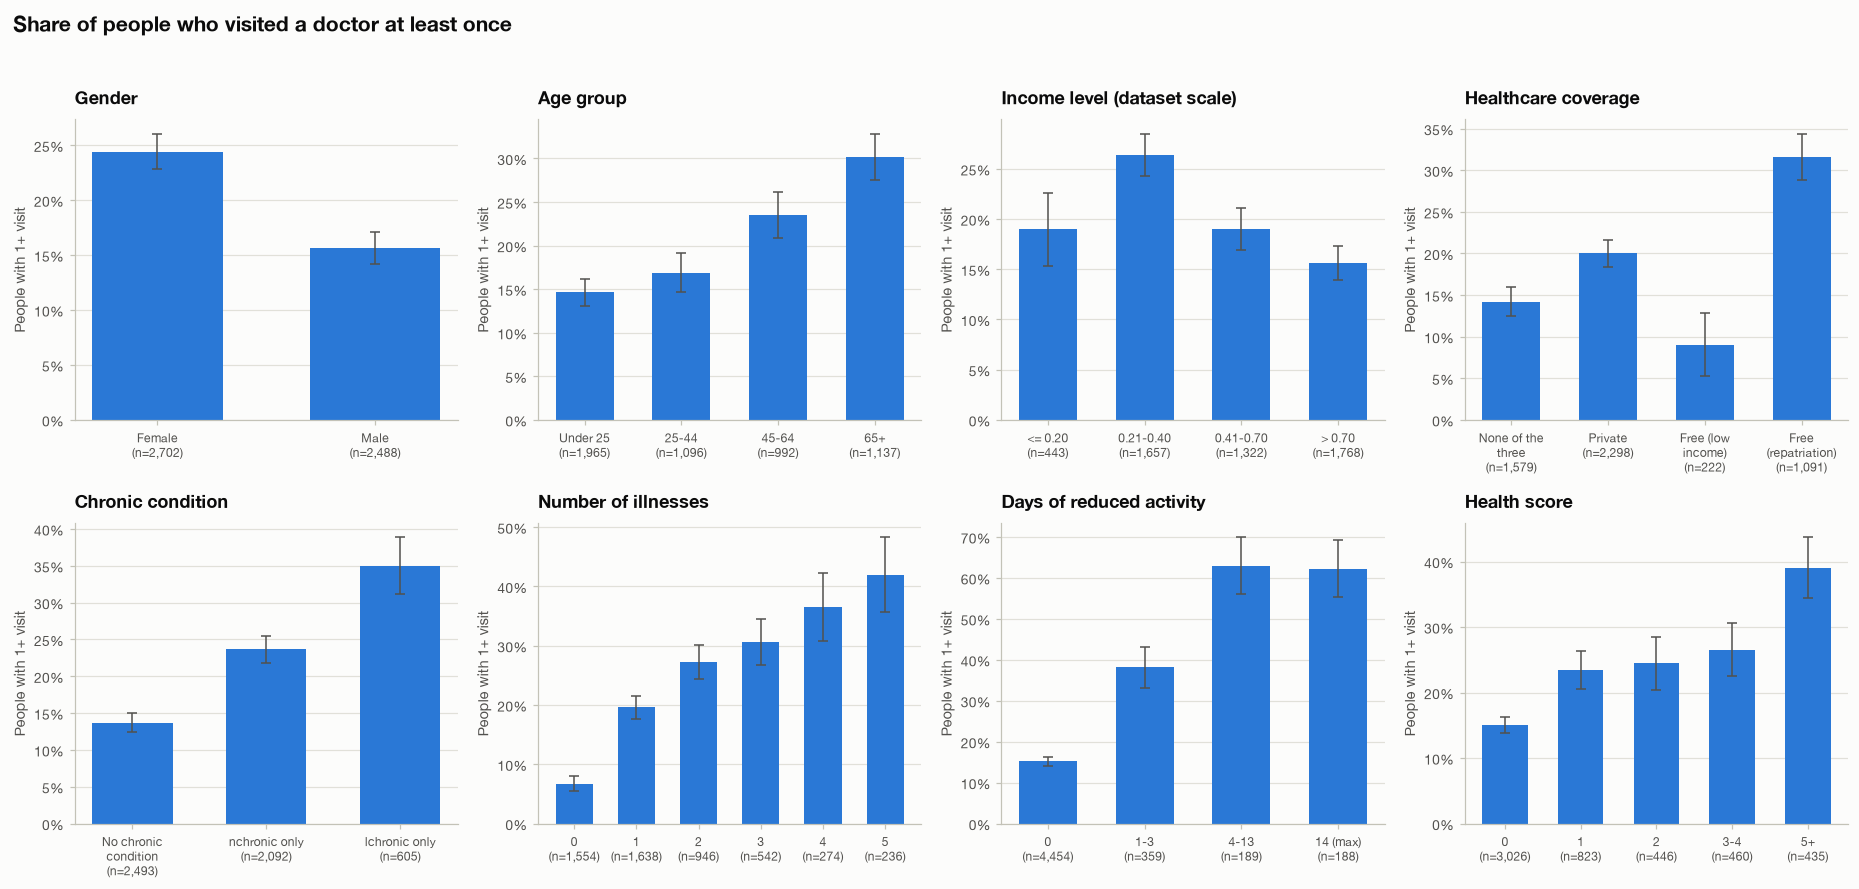

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8.2), sharey=False)
for ax, (col, title) in zip(axes.ravel(), panels):
    group_panel(ax, col, title, value="any_visit", pct=True)
    ax.set_ylabel("People with 1+ visit")
fig.suptitle("Share of people who visited a doctor at least once", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

**What the group comparisons show** (each factor on its own, nothing else held fixed)

* **Gender:** women average 0.36 visits against 0.24 for men; 24.4% of women visited at least once versus 15.6% of men.
* **Age:** the average roughly doubles from 0.21 (under 25) to 0.45 (65+), and the share with a visit climbs from about 15% to 30%.
* **Income:** the pattern is *not* a straight line. Visits peak in the 0.21-0.40 group (0.40) and are lowest in the top group (0.22). The lowest-income group is small (n=443), hence its wide interval.
* **Coverage:** people on **free repatriation cover visit most (0.47)**, private-cover holders average 0.29, the "none" group 0.22, and people on **free low-income cover least (0.16)**. That last group is small (n=222), so its interval is wide.
* **Chronic condition:** 0.19 (none) -> 0.35 (`nchronic`) -> 0.60 (`lchronic`).
* **Health indicators show the sharpest gradients.** Average visits rise from **0.08 with no illnesses to 0.81 with five** (about 10x). People with no reduced-activity days average 0.18 visits against 1.3-1.5 for those with 4+ days, and about 15% of the former visited at all versus over 60% of the latter. The health score rises from 0.20 (score 0) to about 0.70 (score 5+).

### Which factors are statistically associated with visits?

Charts show size; tests show whether a gap could be chance. Because `visits` is a skewed count, we use **rank-based tests** that do not assume a bell curve:

* **Spearman correlation ρ**: direction and strength of the association between `visits` and each factor (−1 to +1; 0 = none). For 0/1 flags this compares the two groups.
* **Kruskal-Wallis test** for the grouped variables (coverage, chronic condition) that have more than two groups.

A p-value below 0.05 is conventionally called "statistically significant". With 5,190 people even small differences can pass, so also look at the size of ρ.

In [13]:
pretty = {
    "female": "Female", "age_years": "Age", "income": "Income", "illness": "Number of illnesses",
    "reduced": "Days of reduced activity", "health": "Health score", "private": "Private cover",
    "freepoor": "Free cover (low income)", "freerepat": "Free cover (repatriation)",
    "nchronic": "Chronic condition (nchronic)", "lchronic": "Chronic condition (lchronic)",
}
pred_cols = list(pretty)

rows = []
for c in pred_cols:
    rho, p = stats.spearmanr(df[c], df["visits"])
    rows.append({"factor": pretty[c], "column": c, "rho": rho, "p_value": p})
assoc = pd.DataFrame(rows)
assoc["significant (p<0.05)"] = np.where(assoc["p_value"] < 0.05, "yes", "no")
assoc = assoc.sort_values("rho", ascending=False).reset_index(drop=True)
assoc.assign(p_value=assoc["p_value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")) \
     .drop(columns="column")

,factor,rho,p_value,significant (p<0.05)
0,Days of reduced activity,0.336,<0.001,yes
1,Number of illnesses,0.263,<0.001,yes
2,Health score,0.178,<0.001,yes
3,Age,0.148,<0.001,yes
4,Free cover (repatriation),0.145,<0.001,yes
5,Chronic condition (lchronic),0.139,<0.001,yes
6,Female,0.108,<0.001,yes
7,Chronic condition (nchronic),0.069,<0.001,yes
8,Private cover,-0.004,0.762,no
9,Free cover (low income),-0.059,<0.001,yes


Kruskal-Wallis, visits across Healthcare coverage groups: H = 138.1, p = 9.9e-30
Kruskal-Wallis, visits across Chronic condition groups: H = 170.6, p = 9e-38


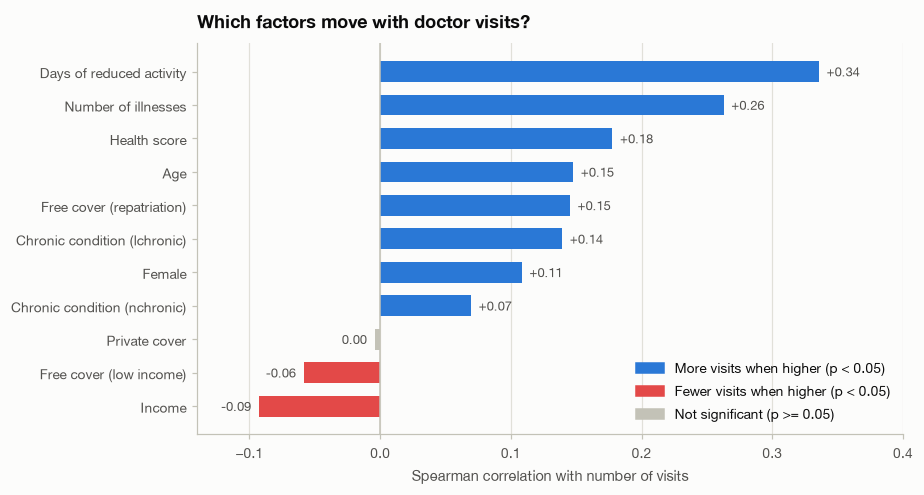

In [14]:
for col, label in [("coverage", "Healthcare coverage"), ("chronic", "Chronic condition")]:
    groups = [g["visits"].values for _, g in df.groupby(col, observed=True)]
    h, p = stats.kruskal(*groups)
    print(f"Kruskal-Wallis, visits across {label} groups: H = {h:.1f}, p = {p:.2g}")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
plot = assoc.sort_values("rho")
colors = [BASELINE if p >= 0.05 else (BLUE if r > 0 else RED) for r, p in zip(plot["rho"], plot["p_value"])]
ax.barh(plot["factor"], plot["rho"], height=0.62, color=colors)
ax.axvline(0, color=BASELINE, linewidth=1)
for y, r in enumerate(plot["rho"]):
    ax.text(r + (0.006 if r >= 0 else -0.006), y, "0.00" if abs(r) < 0.005 else f"{r:+.2f}", va="center",
            ha="left" if r >= 0 else "right", fontsize=8.5, color=INK2)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlim(-0.14, 0.40)
ax.set_xlabel("Spearman correlation with number of visits")
ax.set_title("Which factors move with doctor visits?")
ax.legend(handles=[Patch(color=BLUE, label="More visits when higher (p < 0.05)"),
                   Patch(color=RED, label="Fewer visits when higher (p < 0.05)"),
                   Patch(color=BASELINE, label="Not significant (p >= 0.05)")],
          loc="lower right")
fig.tight_layout()
plt.show()

**Reading the ranking**

* **Health measures lead.** Days of reduced activity (ρ = +0.34), number of illnesses (+0.26) and the health score (+0.18) are the three strongest associations with visits.
* Next come **age** (+0.15), **free repatriation cover** (+0.15), **`lchronic`** (+0.14) and **being female** (+0.11).
* **Income** (-0.09) and **free low-income cover** (-0.06) are weakly *negative*.
* **Private cover shows no association** (ρ ≈ 0, p = 0.76). Section 6 explains why this is misleading.
* Both Kruskal-Wallis tests are highly significant (coverage p ≈ 1e-29, chronic condition p ≈ 1e-37), so visit patterns genuinely differ across coverage types and chronic-condition groups.
* **No factor is strong on its own.** Even the best (reduced-activity days) reaches only ρ = 0.34, so visiting behaviour has many contributing influences.

## 6. How the factors relate to each other

One-factor-at-a-time comparisons can mislead when the factors are tangled together. For example, if older people both visit more *and* are more likely to have a certain kind of coverage, that coverage will look linked to visits even if it has no effect of its own. This is called **confounding**. We look at how the factors overlap, then handle it properly in the models of Section 7.

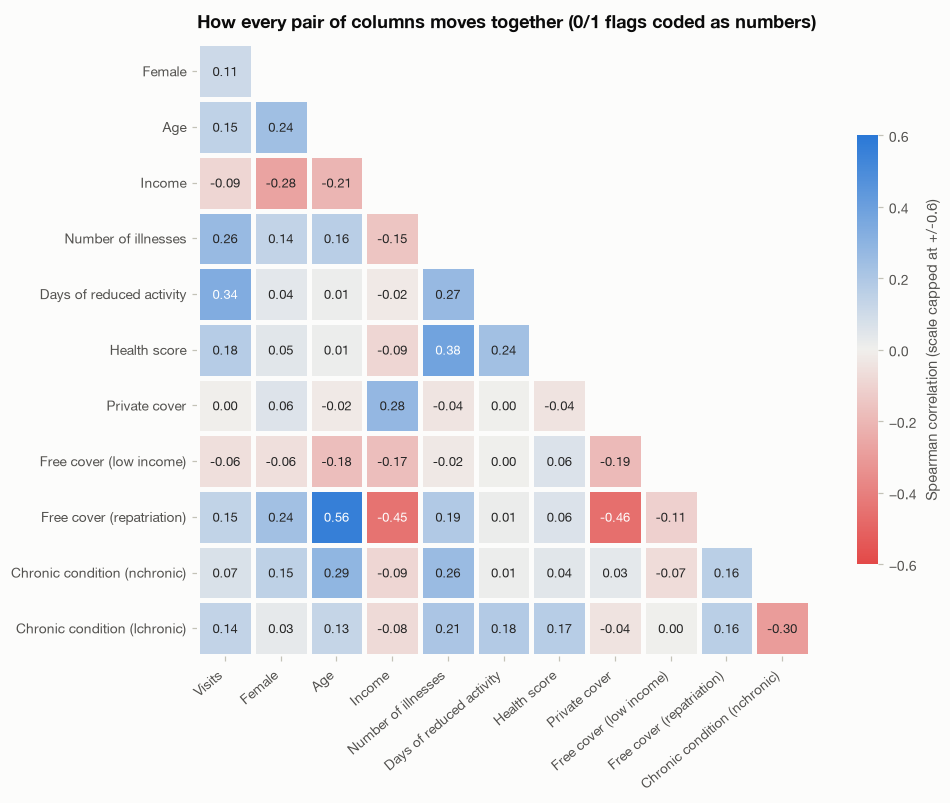

In [15]:
corr_cols = ["visits"] + pred_cols
names = {"visits": "Visits", **pretty}
corr = df[corr_cols].corr(method="spearman").rename(index=names, columns=names)

# Same colour logic as the bar chart above: blue = positive, red = negative, grey = none.
diverging = LinearSegmentedColormap.from_list("red_neutral_blue", [RED, NEUTRAL, BLUE])
sub = corr.iloc[1:, :-1]                                    # drop the diagonal and the mirrored half
mask = np.triu(np.ones_like(sub, dtype=bool), k=1)
labels = sub.map(lambda v: f"{v:.2f}".replace("-0.00", "0.00"))

fig, ax = plt.subplots(figsize=(10, 7.4))
sns.heatmap(sub, mask=mask, cmap=diverging, vmin=-0.6, vmax=0.6, center=0, annot=labels, fmt="",
            annot_kws={"size": 8.5}, linewidths=2, linecolor=SURFACE, square=True,
            cbar_kws={"shrink": 0.7, "label": "Spearman correlation (scale capped at +/-0.6)"}, ax=ax)
ax.grid(False)
ax.set_title("How every pair of columns moves together (0/1 flags coded as numbers)")
ax.tick_params(axis="x", rotation=40)
plt.setp(ax.get_xticklabels(), ha="right")
fig.tight_layout()
plt.show()

In [16]:
profile_cols = {
    "n": ("visits", "size"), "avg age": ("age_years", "mean"), "avg income": ("income", "mean"),
    "avg illnesses": ("illness", "mean"), "avg reduced days": ("reduced", "mean"),
    "avg health score": ("health", "mean"), "avg visits": ("visits", "mean"),
    "% with 1+ visit": ("any_visit", lambda s: s.mean() * 100),
}
print("Who is in each healthcare-coverage group?")
display(df.groupby("coverage", observed=True).agg(**profile_cols).round(2))
print("Who is in each chronic-condition group?")
display(df.groupby("chronic", observed=True).agg(**profile_cols).round(2))

Who is in each healthcare-coverage group?


,n,avg age,avg income,avg illnesses,avg reduced days,avg health score,avg visits,% with 1+ visit
coverage,,,,,,,,
None of the three,1579,28.16,0.65,1.19,0.69,1.12,0.22,14.19
Private,2298,39.33,0.70,1.36,0.77,1.10,0.29,20.02
Free (low income),222,24.99,0.30,1.26,0.77,1.80,0.16,9.01
Free (repatriation),1091,64.64,0.30,1.97,1.33,1.50,0.47,31.62


Who is in each chronic-condition group?


,n,avg age,avg income,avg illnesses,avg reduced days,avg health score,avg visits,% with 1+ visit
chronic,,,,,,,,
No chronic condition,2493,32.80,0.63,0.88,0.45,0.90,0.19,13.72
nchronic only,2092,48.01,0.55,1.85,0.85,1.27,0.35,23.66
lchronic only,605,47.46,0.52,2.27,2.58,2.34,0.60,35.04


**What the overlaps reveal**

* **Free repatriation cover is a different population.** Those people average **65 years old** (vs 28 for "none" and 39 for private), have low income (0.30), and report more illnesses (1.97 vs 1.19-1.36) and more reduced-activity days (1.33 vs 0.69-0.77). Their high visit rate (0.47) is therefore at least partly an age-and-health story. This is the confounding warned about above (age and repatriation cover correlate at 0.56).
* **Why private cover looked unrelated.** The correlation in Section 5 compared private-cover holders with *everyone else*, a mix that includes the high-visiting repatriation group. Compared with the **"none" group**, private-cover holders visit more (20.0% vs 14.2% had at least one visit; 0.29 vs 0.22 average visits).
* **Low-income free cover looks like a puzzle.** This small, young group (average age 25, income 0.30) has the **worst average health score (1.80)** yet the **fewest visits (0.16; 9% visited)**.
* **The chronic-condition groups behave as the guide's wording suggests.** The `lchronic` group averages **2.58 reduced-activity days versus 0.45** for people with no chronic condition, so `lchronic` marks a condition that limits daily activity (the background note's reading). They also have more illnesses (2.27 vs 0.88) and visit more often (35% vs 14% visited).
* **The health measures are only moderately correlated with each other** (at most 0.38), so each carries some independent information. This is confirmed formally in Section 7.4.

Because so many factors are tangled together, we need a model that adjusts for all of them at once.

## 7. Statistical models: the effect of each factor, holding the others fixed

A model lets us ask: *"Comparing two people who are the same on every other factor, what does this one factor change?"* That is how we get past the confounding problem from Section 6.

### 7.1 Choosing a model for counts

`visits` is a count with many zeros, so an ordinary straight-line regression is a poor fit. The standard choices are:

| Model | Idea | Assumption |
|-------|------|-----------|
| **Poisson** | Counts of independent events | The variance equals the mean |
| **Negative binomial (NB)** | Poisson with extra spread | The variance can exceed the mean ("overdispersion") |
| **Zero-inflated NB (ZINB)** | NB plus a separate group of people who *never* visit | Excess zeros beyond what NB predicts |

We fit all three with the same factors and compare how well they match the data. Two rescalings make the results easier to read: **age in 10-year steps** and **income in +0.5 steps**. The income step is one third of the full 0-1.5 range in the data; the guide gives no unit.

In [17]:
df["age_per10y"] = df["age_years"] / 10
df["income_per_half"] = df["income"] / 0.5

terms = ["female", "age_per10y", "income_per_half", "illness", "reduced", "health",
         "private", "freepoor", "freerepat", "nchronic", "lchronic"]
rhs = " + ".join(terms)

model_labels = {
    "female": "Female (vs male)",
    "age_per10y": "Age (+10 years)",
    "income_per_half": "Income (+0.5 on scale)",
    "illness": "Illnesses (+1)",
    "reduced": "Reduced-activity days (+1)",
    "health": "Health score (+1, higher = worse)",
    "private": "Private cover (vs none of the three)",
    "freepoor": "Free cover, low income (vs none)",
    "freerepat": "Free cover, repatriation (vs none)",
    "nchronic": "Chronic condition: nchronic (vs none)",
    "lchronic": "Chronic condition: lchronic (vs none)",
}

# Is the data overdispersed? Cameron-Trivedi auxiliary regression on a plain Poisson fit.
pois = smf.poisson(f"visits ~ {rhs}", df).fit(disp=0)
mu = pois.predict()
aux = ((df["visits"] - mu) ** 2 - df["visits"]) / mu
ct = sm.OLS(aux, mu).fit()
print(f"Raw variance / mean of visits: {df['visits'].var() / df['visits'].mean():.2f}")
print(f"Overdispersion test (Poisson fit): alpha = {ct.params.iloc[0]:.2f}, t = {ct.tvalues.iloc[0]:.1f}, "
      f"p = {ct.pvalues.iloc[0]:.1e}   (alpha > 0 means more spread than Poisson allows)")

Raw variance / mean of visits: 2.11
Overdispersion test (Poisson fit): alpha = 0.96, t = 7.5, p = 7.1e-14   (alpha > 0 means more spread than Poisson allows)


In [18]:
nb = smf.negativebinomial(f"visits ~ {rhs}", df).fit(disp=0, maxiter=200)

# Zero-inflated NB: the count part uses every factor; the "never visits" part uses the
# three health indicators (a person with no illness / no lost days / a good health score
# is the likeliest to have no reason to go).
X = sm.add_constant(df[terms])
Z = sm.add_constant(df[["illness", "reduced", "health"]])
zinb = sm.ZeroInflatedNegativeBinomialP(df["visits"], X, exog_infl=Z, inflation="logit") \
         .fit(method="bfgs", maxiter=1000, disp=0)
print("ZINB converged:", zinb.mle_retvals["converged"], "| NB converged:", nb.mle_retvals["converged"])

fits = {"Poisson": pois, "Negative binomial": nb, "Zero-inflated NB": zinb}
comparison = pd.DataFrame({
    name: {"parameters": len(res.params), "log-likelihood": res.llf, "AIC": res.aic, "BIC": res.bic}
    for name, res in fits.items()
}).T
comparison["AIC vs best"] = comparison["AIC"] - comparison["AIC"].min()
comparison.round(1)

ZINB converged: True | NB converged: True


,parameters,log-likelihood,AIC,BIC,AIC vs best
Poisson,12.0,-3355.9,6735.7,6814.4,418.3
Negative binomial,13.0,-3198.8,6423.7,6508.9,106.3
Zero-inflated NB,17.0,-3141.7,6317.4,6428.8,0.0


**AIC and BIC** score how well a model fits *after* penalising complexity, and lower is better. A drop of more than about 10 is considered strong evidence of a better model.

Next, a more intuitive check: **how many people does each model expect at each visit count, compared with what we actually see?**

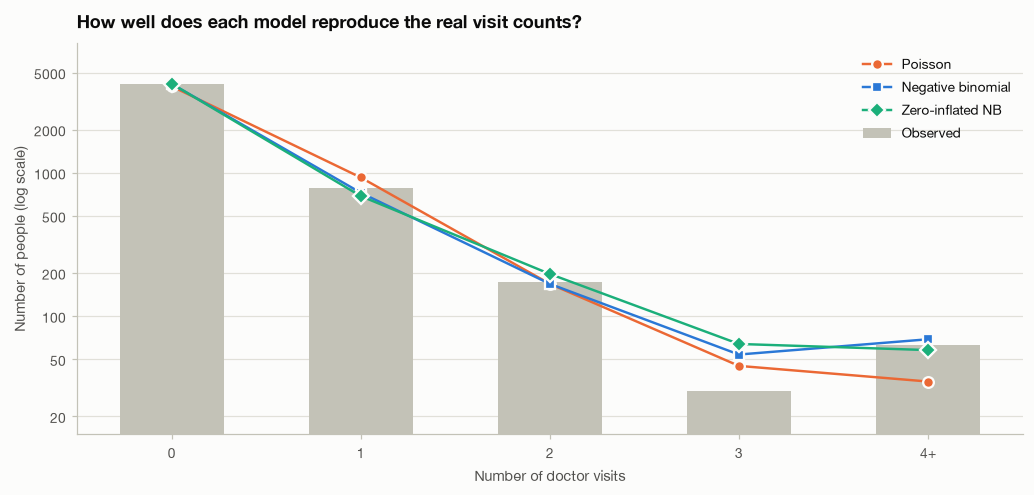

,Observed,Poisson,Negative binomial,Zero-inflated NB
0,4141,4014.0,4173.0,4183.0
1,782,928.0,726.0,688.0
2,174,168.0,168.0,197.0
3,30,45.0,54.0,64.0
4+,63,35.0,69.0,58.0


In [19]:
def expected_counts(res, kmax=4):
    p = np.asarray(res.predict(which="prob"))          # person x count probabilities
    exp = p.sum(axis=0)
    return np.append(exp[:kmax], len(df) - exp[:kmax].sum())   # last bin = kmax and above


cats = ["0", "1", "2", "3", "4+"]
obs = np.append(df["visits"].value_counts().sort_index().reindex(range(4), fill_value=0).values,
                (df["visits"] >= 4).sum())
fit_table = pd.DataFrame({"Observed": obs, **{n: expected_counts(r) for n, r in fits.items()}}, index=cats).round(0)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
x = np.arange(len(cats))
ax.bar(x, obs, width=0.55, color=BASELINE, label="Observed")
for (name, color, marker) in [("Poisson", ORANGE, "o"), ("Negative binomial", BLUE, "s"), ("Zero-inflated NB", AQUA, "D")]:
    ax.plot(x, fit_table[name], color=color, marker=marker, markersize=7, linewidth=1.6,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=name)
ax.set_yscale("log")
ax.set_ylim(15, 8000)
ax.set_xticks(x); ax.set_xticklabels(cats)
ax.set_yticks([20, 50, 100, 200, 500, 1000, 2000, 5000])
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.minorticks_off()
ax.set_xlabel("Number of doctor visits")
ax.set_ylabel("Number of people (log scale)")
ax.set_title("How well does each model reproduce the real visit counts?")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

fit_table

**Which model fits best?**

* **Poisson is rejected.** The overdispersion test is clearly significant (α = 0.96, p ≈ 7e-14), consistent with the raw variance-to-mean ratio of 2.11.
* **Negative binomial fits far better.** Its AIC is **312 points lower** than Poisson's (6,423.7 vs 6,735.7). The **zero-inflated NB is better still** (6,317.4, another 106 lower), and it also has the lowest BIC.
* **The expected-count table shows where Poisson goes wrong.** It over-predicts people with exactly one visit (928 expected vs 782 observed) and badly under-predicts heavy users (35 expected with four or more vs 63 observed). NB gets the 4+ group almost right (69), and both NB and ZINB match the number of zero-visit people (observed 4,141 vs 4,173 and 4,183 expected).
* **Neither model is perfect.** Both over-predict the three-visit group (observed 30 vs 54 and 64 expected), and ZINB under-predicts one-visit people (688 vs 782).

**Decision:** the models agree on the essential structure (strong overdispersion, heavy tail). We interpret the **negative binomial** model because it is simpler and gives a single set of coefficients, and we cross-check it with the logistic model below. The zero-inflated model's AIC edge comes from a second, separate "never visits" component, which is harder to read and not needed for the questions here.

### 7.2 Reading the negative binomial model: incidence rate ratios

We interpret the **negative binomial** model because it has one easy-to-read set of coefficients. Its coefficients are turned into **incidence rate ratios (IRR)**:

* IRR = 1.00: no effect;
* IRR = 1.25: the expected number of visits is **25% higher**;
* IRR = 0.60: the expected number of visits is **40% lower**.

All comparisons are *holding every other factor fixed*. The interval is the 95% confidence interval; if it crosses 1.00, the data cannot rule out "no effect".

,estimate,ci_low,ci_high,p_value
Female (vs male),1.24,1.08,1.42,0.002
Illnesses (+1),1.24,1.18,1.30,<0.001
Chronic condition: lchronic (vs none),1.20,0.98,1.47,0.076
"Free cover, repatriation (vs none)",1.16,0.92,1.46,0.211
Reduced-activity days (+1),1.15,1.14,1.17,<0.001
Private cover (vs none of the three),1.12,0.95,1.33,0.171
Chronic condition: nchronic (vs none),1.10,0.95,1.29,0.214
"Health score (+1, higher = worse)",1.04,1.01,1.07,0.006
Age (+10 years),1.03,0.99,1.08,0.112
Income (+0.5 on scale),0.92,0.84,1.02,0.130


NB dispersion alpha = 1.08 (95% CI 0.87-1.28); alpha = 0 would mean plain Poisson.


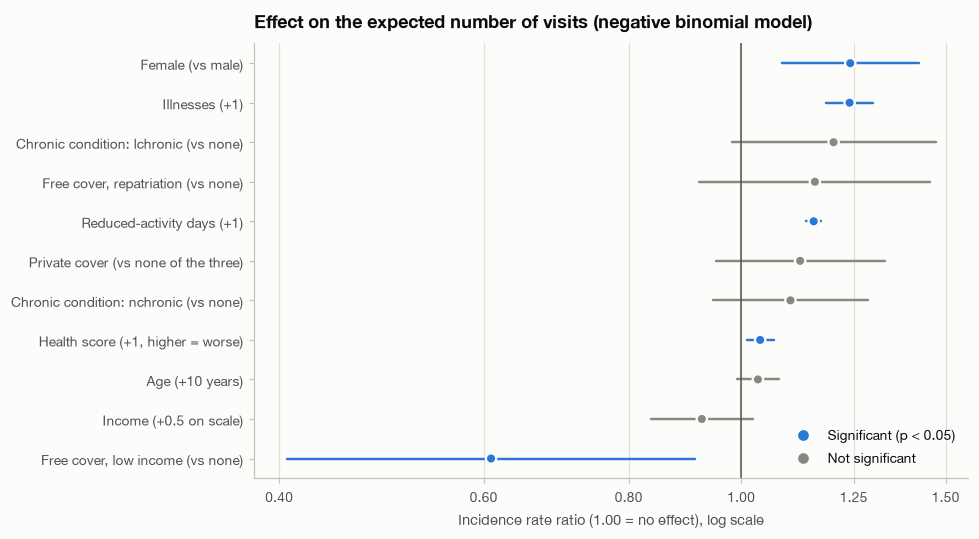

In [20]:
def coef_table(res, names, exp=True):
    params = res.params[names]
    ci = res.conf_int().loc[names]
    out = pd.DataFrame({"estimate": params, "ci_low": ci[0], "ci_high": ci[1], "p_value": res.pvalues[names]})
    if exp:
        out[["estimate", "ci_low", "ci_high"]] = np.exp(out[["estimate", "ci_low", "ci_high"]])
    out.index = [model_labels[n] for n in names]
    return out


def forest(ax, tab, title, xlabel):
    tab = tab.sort_values("estimate")
    y = np.arange(len(tab))
    sig = tab["p_value"] < 0.05
    colors = np.where(sig, BLUE, MUTED)
    for yi, (_, r), c in zip(y, tab.iterrows(), colors):
        ax.plot([r["ci_low"], r["ci_high"]], [yi, yi], color=c, linewidth=1.6, solid_capstyle="round")
    ax.scatter(tab["estimate"], y, s=46, color=colors, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.axvline(1, color=INK2, linewidth=1)
    ax.set_yticks(y); ax.set_yticklabels(tab.index)
    ax.set_xscale("log")
    ticks = [0.4, 0.6, 0.8, 1, 1.25, 1.5, 2, 3]
    lo, hi = tab["ci_low"].min(), tab["ci_high"].max()
    ticks = [t for t in ticks if lo * 0.85 <= t <= hi * 1.15]
    ax.set_xticks(ticks); ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.minorticks_off()
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.set_xlabel(xlabel); ax.set_title(title)
    ax.legend(handles=[Line2D([], [], marker="o", color=BLUE, linestyle="", label="Significant (p < 0.05)"),
                       Line2D([], [], marker="o", color=MUTED, linestyle="", label="Not significant")],
              loc="lower right")


irr = coef_table(nb, terms)
shown = irr.assign(p_value=irr["p_value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")).round(2)
display(shown.sort_values("estimate", ascending=False))
print(f"NB dispersion alpha = {nb.params['alpha']:.2f} (95% CI {nb.conf_int().loc['alpha', 0]:.2f}-{nb.conf_int().loc['alpha', 1]:.2f}); "
      f"alpha = 0 would mean plain Poisson.")

fig, ax = plt.subplots(figsize=(9, 5))
forest(ax, irr, "Effect on the expected number of visits (negative binomial model)",
       "Incidence rate ratio (1.00 = no effect), log scale")
fig.tight_layout()
plt.show()

**What the negative binomial model says** (each effect holds all other factors fixed)

* **Illness and lost activity days are the clearest drivers.** Each extra illness raises expected visits by about **24%** (IRR 1.24, CI 1.18-1.30). Each extra reduced-activity day adds about **15%** (1.15, CI 1.14-1.17). Each point on the health score adds about **4%** (1.04, CI 1.01-1.07).
* **Women visit more.** Expected visits are about **24% higher** than for men with the same age, health and coverage (1.24, CI 1.08-1.42).
* **Free low-income cover is linked to about 39% fewer visits** (IRR 0.61, CI 0.41-0.91), even though we hold health fixed. The group is small (n=222), so the interval is wide.
* **Several raw patterns fade once health is held fixed:**
  * age: only +3% per decade (CI 0.99-1.08), not distinguishable from zero;
  * income: IRR 0.92 (CI 0.84-1.02), also not distinguishable from zero;
  * `lchronic`: 1.20 (CI 0.98-1.47, p = 0.076), borderline;
  * `nchronic`, private cover and free repatriation cover: all with intervals that include 1.00 (p = 0.17-0.21).

  This suggests age, income and chronic conditions matter mostly *through* health: older and chronically ill people are sicker, and it is the sickness that drives visits.
* **Dispersion α = 1.08** (CI 0.87-1.28): even after adjusting for everything, there is a lot of person-to-person variation left unexplained.

### 7.3 A second view: the chance of visiting at all

Because ~80% of people made no visit, "did they visit at all?" is a natural question by itself. A **logistic regression** models the chance of **at least one visit**; coefficients become **odds ratios (OR)** (OR 1.30 = 30% higher odds of visiting).

To check the model is predictive and not just descriptive, we also report a **cross-validated AUC** (5 folds). An AUC of 0.5 is a coin flip and 1.0 is perfect; each fold is scored on people the model was not trained on.

,estimate,ci_low,ci_high,p_value
"Free cover, repatriation (vs none)",1.52,1.16,2.00,0.003
Illnesses (+1),1.31,1.23,1.38,<0.001
Female (vs male),1.30,1.10,1.52,0.002
Private cover (vs none of the three),1.30,1.07,1.58,0.010
Chronic condition: lchronic (vs none),1.27,0.99,1.62,0.059
Reduced-activity days (+1),1.17,1.14,1.20,<0.001
Chronic condition: nchronic (vs none),1.10,0.92,1.31,0.298
"Health score (+1, higher = worse)",1.06,1.03,1.10,<0.001
Age (+10 years),1.05,1.00,1.10,0.054
Income (+0.5 on scale),0.97,0.86,1.10,0.646


Cross-validated AUC: 0.751 +/- 0.017   (in-sample AUC 0.757)
McFadden pseudo R-squared: 0.127


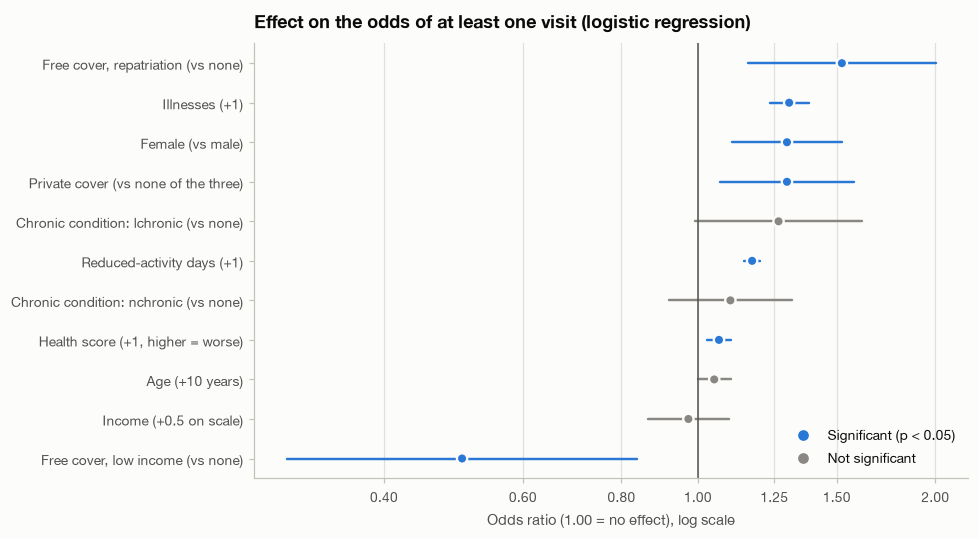

In [21]:
logit = smf.logit(f"any_visit ~ {rhs}", df).fit(disp=0)
orr = coef_table(logit, terms)
display(orr.assign(p_value=orr["p_value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"))
        .round(2).sort_values("estimate", ascending=False))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
auc = cross_val_score(clf, df[terms], df["any_visit"], cv=cv, scoring="roc_auc")
print(f"Cross-validated AUC: {auc.mean():.3f} +/- {auc.std():.3f}   (in-sample AUC {roc_auc_score(df['any_visit'], logit.predict(df)):.3f})")
print(f"McFadden pseudo R-squared: {logit.prsquared:.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
forest(ax, orr, "Effect on the odds of at least one visit (logistic regression)",
       "Odds ratio (1.00 = no effect), log scale")
fig.tight_layout()
plt.show()

**What the logistic model says about *whether* someone visits**

The picture matches the count model, with one notable difference in coverage:

* **Illnesses** (OR 1.31 per illness), **reduced-activity days** (1.17 per day), **health score** (1.06 per point) and **being female** (1.30) all raise the odds of a visit.
* **Coverage matters more for *whether* people visit than for *how many times*.** Compared with the "none" group, **free repatriation cover** has 52% higher odds of at least one visit (OR 1.52, CI 1.16-2.00) and **private cover** 30% higher (OR 1.30, CI 1.07-1.58), whereas in the count model these two had no clear effect. This is suggestive rather than proven: a difference in significance is not the same as a significant difference.
* **Free low-income cover again stands out:** the odds of any visit are **half** those of the "none" group (OR 0.50, CI 0.30-0.84).
* Age (OR 1.05 per decade, p = 0.054) and `lchronic` (1.27, p = 0.059) are borderline; income is not significant (0.97).
* **Predictive power is moderate.** The cross-validated AUC is **0.75**: pick one person who visited and one who did not, and the model ranks the visitor higher about three times in four. The pseudo-R² of 0.13 says most of the variation between people is not captured by these 11 columns.

### 7.4 Model checks

**Multicollinearity** means two factors carry nearly the same information, which makes their separate effects hard to untangle. The variance inflation factor (VIF) measures this; values below about 5 are comfortable.

In [22]:
Xv = sm.add_constant(df[terms])
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=[model_labels[t] for t in terms], name="VIF")
vif.sort_values(ascending=False).round(2).to_frame()

,VIF
"Free cover, repatriation (vs none)",2.45
Age (+10 years),1.91
Private cover (vs none of the three),1.56
Chronic condition: nchronic (vs none),1.38
Illnesses (+1),1.36
Income (+0.5 on scale),1.35
Chronic condition: lchronic (vs none),1.32
"Health score (+1, higher = worse)",1.23
Female (vs male),1.19
"Free cover, low income (vs none)",1.15


All VIFs are **below 2.5** (highest: free repatriation cover at 2.45, linked to age and income), so multicollinearity is not a concern and the coefficients above can be read at face value.

## 8. Key findings and caveats

### Answering the guiding question: *why do some people visit a doctor more often than others?*

1. **Most people do not visit at all.** About 80% had zero visits and the variance is twice the mean, so counts need a model that allows extra spread (negative binomial or zero-inflated), not a plain Poisson or straight-line regression.
2. **Health status is the main driver.** The three health measures have the strongest associations with visits, and they stay strong after adjusting for everything else: each extra illness is linked to about **24% more visits**, each reduced-activity day to about **15% more**, and each health-score point to about **4% more**.
3. **Women visit more**, even after adjusting for age, health and coverage: about **24% more visits** and **30% higher odds** of visiting at all.
4. **Age, income and chronic condition look important on their own but mostly work through health.** Raw gaps are large (65+ average 0.45 visits vs 0.21 under 25; `lchronic` 0.60 vs 0.19 with no chronic condition), but once illness and reduced-activity days are held fixed, age and income are no longer clearly different from zero and `lchronic` is borderline.
5. **Healthcare coverage is easy to misread.**
   * People on **free repatriation cover** have the highest raw visit rate (0.47), but they are also much older (about 65) and sicker. After adjustment they have **higher odds of visiting at all** (OR 1.52) but no clearly higher visit *count* (IRR 1.16, not significant).
   * **Private cover** shows no raw association with visits (it is compared against a mixed group), but versus the "none" group it carries about **30% higher odds** of at least one visit (OR 1.30).
6. **The one group that stands out as under-using care: free cover for low income.** Despite the worst average health score of any coverage group, they visit least (0.16 average, 9% with any visit). After adjustment they still have about **39% fewer expected visits** and **half the odds** of any visit. This group is small (n=222), so the estimates are imprecise, but the finding appears in every view and merits a closer look.
7. **Predictability is moderate.** The logistic model separates visitors from non-visitors with a cross-validated AUC of **0.75** (pseudo-R² 0.13). The 11 available columns leave most person-to-person variation unexplained.

### Caveats

* **Association, not causation.** This is observational data. For example, we cannot say private cover *causes* more visits, only that the two go together after adjusting for what is measured.
* **Overlapping health measures.** `illness`, `reduced`, `health` and the chronic flags all reflect the same underlying sickness, so their individual coefficients should not be over-interpreted. What is solid is the combined message: sicker people visit more.
* **Small groups.** Free low-income cover (n=222) has wide intervals; results near p ≈ 0.05 (age, `lchronic`) should be treated as suggestive. We ran many comparisons without adjusting for multiple testing.
* **Coarse and loosely documented variables.** Age comes in 12 brackets, income and `health` have no stated units in the guide, and the guide does not state the time window for `visits`. The background note suggests a two-week window from a late-1970s Australian survey, so the *patterns* are informative but the *levels* may not match today's healthcare systems.
* **Model choice.** The zero-inflated negative binomial scored best on AIC, while the negative binomial was used for interpretation for readability. Both reproduce the data's key features; neither is perfect (e.g. both over-predict three-visit people).
* **Identical rows.** The 1,320 rows that duplicate another row on all measurements were kept as they are plausible given the coarse coding, but with no person identifier this cannot be confirmed.

### Possible next steps

* Fit a **hurdle model** (one model for *whether* someone visits, another for *how many* visits among visitors) to formalise the two-part picture seen in Section 7.
* Test **interactions** (for example age × gender, or coverage × health) and **non-linear effects**. Reduced-activity days, for instance, level off between 4-13 and 14 days.
* Explore why the **low-income free-cover** group visits so little despite poor health (access, eligibility, unmet need), ideally with data that records reasons for not visiting.